#IMPORT NECESSARY LIBRARIES


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import joblib
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)

#DATA COLLECTION

In [2]:
return_predict = pd.read_csv("dataset/returns_dataset.csv")

#DATA UNDERSTANDING

In [3]:
print(return_predict.shape)
return_predict.head(3)

(12000, 26)


,order_id,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,...,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,ORD100000,Beauty,Haircare,Brand_23,844.10,65.2,2.1,96.0,1,1,...,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,ORD100001,Toys,Educational,Brand_9,559.90,30.1,4.1,87.0,0,1,...,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0
2,ORD100002,Electronics,Laptops,Brand_21,1581.93,53.4,3.0,75.0,0,0,...,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,0


# EDA (EXPLORATORY DATA ANALYSIS)

In [4]:
returned_val = return_predict.returned.value_counts()
print(returned_val)

returned
0    8355
1    3645
Name: count, dtype: int64


In [5]:
print((return_predict['returned'].value_counts(normalize = True) * 100).round(2))

returned
0    69.62
1    30.38
Name: proportion, dtype: float64


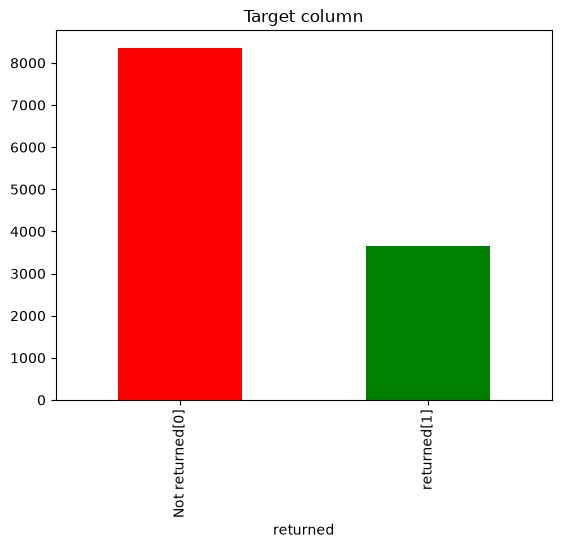

In [6]:
ax = returned_val.plot(kind = "bar", color = ["red", "green"])
ax.set_xticklabels(["Not returned[0]", "returned[1]"])
ax.set_title("Target column")
plt.show()

In [7]:
return_predict.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   order_id                  12000 non-null  str    
 1   product_category          12000 non-null  str    
 2   sub_category              12000 non-null  str    
 3   brand                     12000 non-null  str    
 4   product_price             12000 non-null  float64
 5   discount_percent          12000 non-null  float64
 6   product_rating            11760 non-null  float64
 7   review_count              11880 non-null  float64
 8   fragile_item              12000 non-null  int64  
 9   warranty_available        12000 non-null  int64  
 10  product_return_rate       12000 non-null  float64
 11  category_return_rate      12000 non-null  float64
 12  brand_return_rate         12000 non-null  float64
 13  defect_rate               12000 non-null  float64
 14  seller_rating    

In [8]:
return_predict.describe().T

,count,mean,std,min,25%,50%,75%,max
product_price,12000.0,964.063342,1678.771489,19.510,328.235,597.470,1105.395,64878.670
discount_percent,12000.0,33.567167,19.378304,0.000,16.800,33.500,50.400,67.000
product_rating,11760.0,3.886505,0.635664,1.600,3.500,3.900,4.300,5.000
review_count,11880.0,69.437205,18.446294,24.000,54.000,69.000,85.000,116.000
fragile_item,12000.0,0.197083,0.397812,0.000,0.000,0.000,0.000,1.000
warranty_available,12000.0,0.446500,0.497150,0.000,0.000,0.000,1.000,1.000
product_return_rate,12000.0,0.132522,0.069787,0.001,0.082,0.134,0.183,0.367
category_return_rate,12000.0,0.120377,0.049559,0.001,0.087,0.120,0.154,0.354
brand_return_rate,12000.0,0.131886,0.059397,0.010,0.090,0.135,0.176,0.322
defect_rate,12000.0,0.060629,0.042730,0.000,0.029,0.051,0.082,0.370


<Axes: >

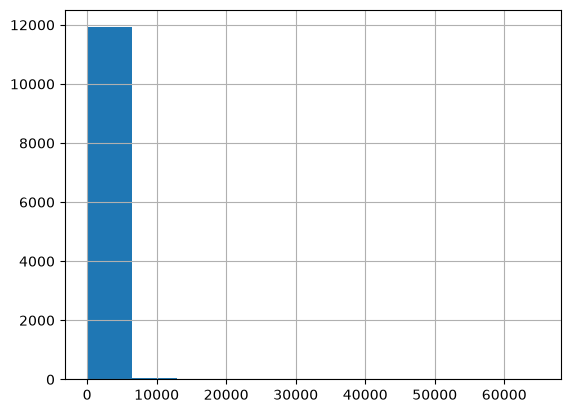

In [9]:
return_predict['product_price'].hist()

In [10]:
return_predict.isna().sum()

order_id                      0
product_category              0
sub_category                  0
brand                         0
product_price                 0
discount_percent              0
product_rating              240
review_count                120
fragile_item                  0
warranty_available            0
product_return_rate           0
category_return_rate          0
brand_return_rate             0
defect_rate                   0
seller_rating               180
seller_return_rate            0
fulfillment_type              0
payment_method                0
quantity                      0
shipping_distance_km        120
delayed_delivery              0
wishlist_before_purchase      0
product_page_views            0
customer_support_calls        0
chat_interactions             0
returned                      0
dtype: int64

In [11]:
categorical_columns = ['product_category', 'sub_category', 'brand', 'fulfillment_type', 'payment_method']
for col in categorical_columns:
    print(return_predict[col].value_counts())
    print()

product_category
Fashion        3413
Electronics    2601
Home           1816
Beauty         1453
Sports         1202
Books           910
Toys            605
Name: count, dtype: int64

sub_category
Mobiles           904
Audio             862
Laptops           835
Women             706
Accessories       684
Footwear          681
Men               673
Kids              669
Furniture         614
Kitchen           614
Decor             588
Haircare          505
Skincare          485
Makeup            463
Team Sports       439
Fitness           389
Outdoor           374
Non-Fiction       335
Fiction           288
Academic          287
Outdoor Play      220
Educational       195
Action Figures    190
Name: count, dtype: int64

brand
Brand_26    442
Brand_21    431
Brand_24    427
Brand_1     425
Brand_15    420
Brand_22    418
Brand_5     418
Brand_11    413
Brand_9     411
Brand_30    410
Brand_7     408
Brand_2     407
Brand_19    406
Brand_14    405
Brand_25    403
Brand_29    400
Brand_4 

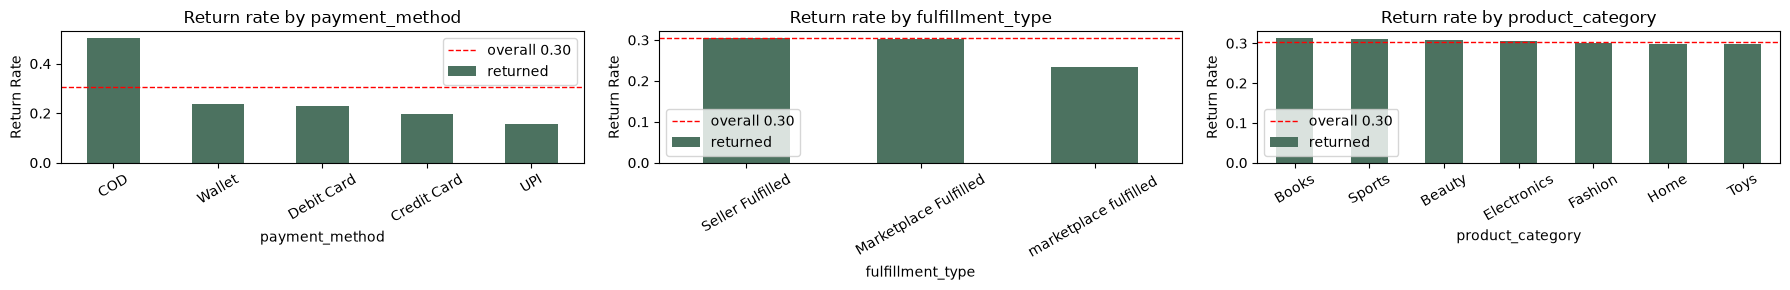

In [12]:
fig, axes = plt.subplots(1,3, figsize=(18, 3))
overall = return_predict['returned'].mean()
for ax, col in zip(axes, ["payment_method", "fulfillment_type", "product_category"]):
    rate = return_predict.groupby(col)["returned"].mean().sort_values(ascending = False)
    rate.plot(kind = "bar", ax = ax, color = "#4c7260")
    ax.axhline(y = overall, color = "red", ls = "--", lw = 1, label = f"overall {overall:.2f}")
    ax.set_title(f"Return rate by {col}"); ax.set_ylabel("Return Rate")
    ax.tick_params(axis = "x", rotation = 30); ax.legend()
plt.tight_layout()
plt.show()

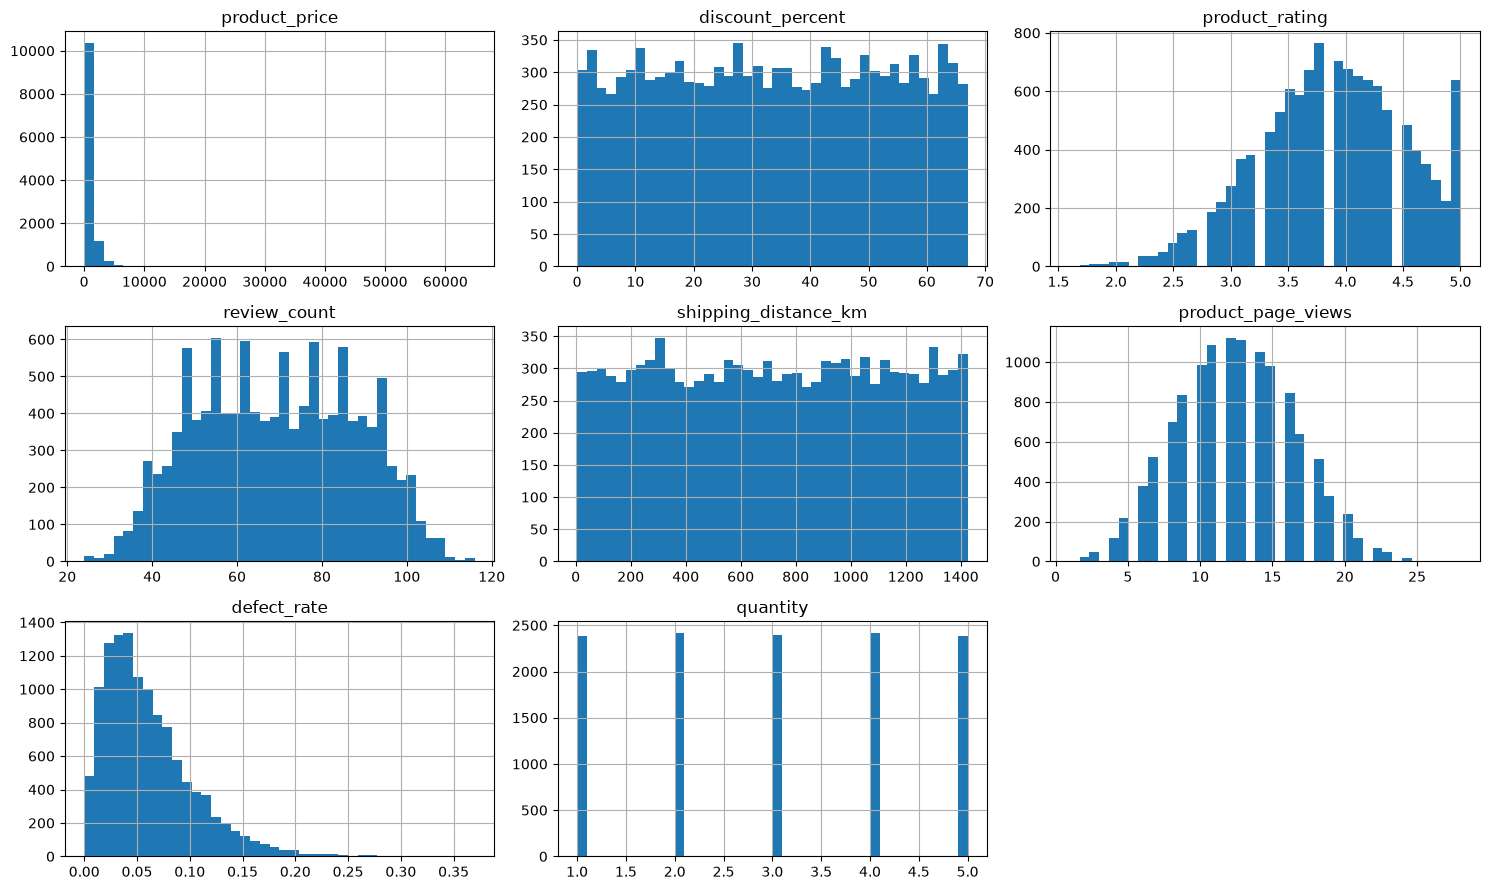

In [13]:
num_show = ["product_price", "discount_percent", "product_rating", "review_count", "shipping_distance_km", "product_page_views", "defect_rate", "quantity"]
return_predict[num_show].hist(figsize = (15, 9), bins = 40)
plt.tight_layout()
plt.show()

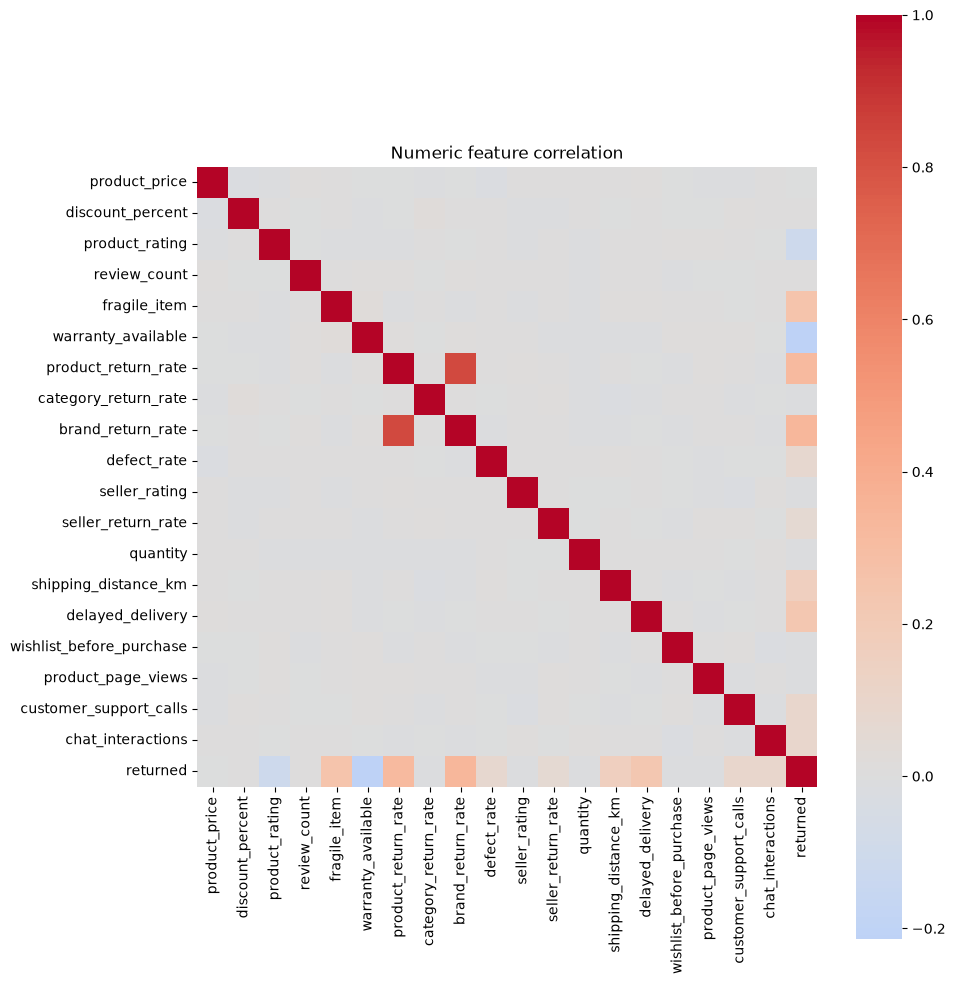

In [14]:
plt.figure(figsize = (10, 12))
corr = return_predict.select_dtypes(include = np.number).corr()
sns.heatmap(corr, cmap = "coolwarm", center = 0, square = True)
plt.title("Numeric feature correlation")
plt.show()
returned_corr = corr["returned"].drop("returned")
returned_corr = returned_corr.reindex(returned_corr.abs().sort_values(ascending = False).index).round(3)

In [15]:
return_predict['fulfillment_type'].value_counts()

fulfillment_type
Marketplace Fulfilled     7193
Seller Fulfilled          4747
marketplace fulfilled       60
Name: count, dtype: int64

In [16]:
return_predict_clean = return_predict.copy()

In [17]:
return_predict_clean["fulfillment_type"] = return_predict_clean["fulfillment_type"].astype("string").str.strip().str.title()

In [18]:
return_predict_clean["fulfillment_type"].value_counts()

fulfillment_type
Marketplace Fulfilled    7253
Seller Fulfilled         4747
Name: count, dtype: Int64

In [19]:
return_predict.head()

,order_id,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,...,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,ORD100000,Beauty,Haircare,Brand_23,844.10,65.2,2.1,96.0,1,1,...,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,ORD100001,Toys,Educational,Brand_9,559.90,30.1,4.1,87.0,0,1,...,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0
2,ORD100002,Electronics,Laptops,Brand_21,1581.93,53.4,3.0,75.0,0,0,...,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,0
3,ORD100003,Electronics,Laptops,Brand_30,1301.55,25.3,3.8,57.0,0,1,...,Marketplace Fulfilled,Credit Card,4,164.5,0,1,9,0,1,0
4,ORD100004,Electronics,Laptops,Brand_15,1402.90,30.6,3.0,71.0,0,1,...,Marketplace Fulfilled,Credit Card,4,474.4,0,0,12,0,0,0


In [20]:
return_predict_clean = return_predict_clean.drop(columns = ['order_id'])

In [21]:
return_predict.head()


,order_id,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,...,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,ORD100000,Beauty,Haircare,Brand_23,844.10,65.2,2.1,96.0,1,1,...,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,ORD100001,Toys,Educational,Brand_9,559.90,30.1,4.1,87.0,0,1,...,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0
2,ORD100002,Electronics,Laptops,Brand_21,1581.93,53.4,3.0,75.0,0,0,...,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,0
3,ORD100003,Electronics,Laptops,Brand_30,1301.55,25.3,3.8,57.0,0,1,...,Marketplace Fulfilled,Credit Card,4,164.5,0,1,9,0,1,0
4,ORD100004,Electronics,Laptops,Brand_15,1402.90,30.6,3.0,71.0,0,1,...,Marketplace Fulfilled,Credit Card,4,474.4,0,0,12,0,0,0


In [22]:
return_predict_clean.head()

,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,...,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,Beauty,Haircare,Brand_23,844.10,65.2,2.1,96.0,1,1,0.172,...,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,Toys,Educational,Brand_9,559.90,30.1,4.1,87.0,0,1,0.168,...,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0
2,Electronics,Laptops,Brand_21,1581.93,53.4,3.0,75.0,0,0,0.045,...,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,0
3,Electronics,Laptops,Brand_30,1301.55,25.3,3.8,57.0,0,1,0.066,...,Marketplace Fulfilled,Credit Card,4,164.5,0,1,9,0,1,0
4,Electronics,Laptops,Brand_15,1402.90,30.6,3.0,71.0,0,1,0.183,...,Marketplace Fulfilled,Credit Card,4,474.4,0,0,12,0,0,0


In [23]:
len(return_predict_clean)

12000

In [24]:
return_predict_clean.drop_duplicates().reset_index(drop = True)

,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,...,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,Beauty,Haircare,Brand_23,844.10,65.2,2.1,96.0,1,1,0.172,...,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,Toys,Educational,Brand_9,559.90,30.1,4.1,87.0,0,1,0.168,...,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0
2,Electronics,Laptops,Brand_21,1581.93,53.4,3.0,75.0,0,0,0.045,...,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,0
3,Electronics,Laptops,Brand_30,1301.55,25.3,3.8,57.0,0,1,0.066,...,Marketplace Fulfilled,Credit Card,4,164.5,0,1,9,0,1,0
4,Electronics,Laptops,Brand_15,1402.90,30.6,3.0,71.0,0,1,0.183,...,Marketplace Fulfilled,Credit Card,4,474.4,0,0,12,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,Home,Furniture,Brand_18,246.32,50.8,4.4,81.0,1,0,0.095,...,Marketplace Fulfilled,COD,5,393.3,0,0,10,0,2,1
11996,Books,Academic,Brand_20,218.97,10.3,3.4,47.0,0,1,0.133,...,Marketplace Fulfilled,Credit Card,2,96.8,0,1,7,1,0,0
11997,Electronics,Laptops,Brand_13,1463.52,32.6,4.3,77.0,1,0,0.184,...,Marketplace Fulfilled,Credit Card,3,1218.5,0,1,14,1,0,0
11998,Electronics,Mobiles,Brand_5,96.32,13.1,4.1,91.0,1,1,0.048,...,Seller Fulfilled,Credit Card,3,337.3,0,0,7,0,0,0


,product_category,sub_category,brand,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,...,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,returned,total_support_contacts,log_price
0,Beauty,Haircare,Brand_23,65.2,2.1,96.0,1,1,0.172,0.173,...,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,1,0,6.739455
1,Toys,Educational,Brand_9,30.1,4.1,87.0,0,1,0.168,0.125,...,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,6.329543
2,Electronics,Laptops,Brand_21,53.4,3.0,75.0,0,0,0.045,0.125,...,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,7.367033


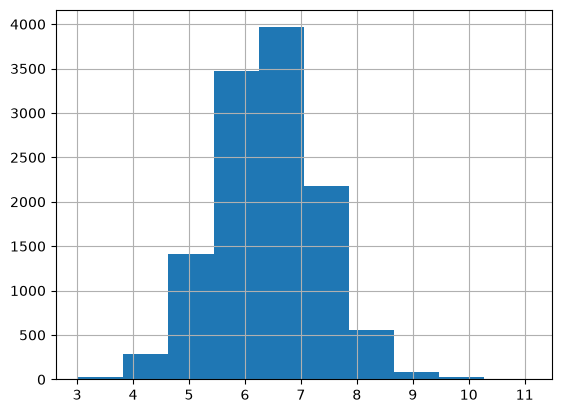

In [25]:
def add_features(d):
    d['total_support_contacts'] = d["customer_support_calls"] + d["chat_interactions"]
    d['log_price'] = np.log1p(d['product_price'])
    d = d.drop(columns = ["product_price", "customer_support_calls", "chat_interactions"])
    return d
df_feat = add_features(return_predict_clean)
df_feat['log_price'].hist()
df_feat.head(3)

In [26]:
df_feat.to_csv("dataset/cleared_returns.csv", index = False)
new_cols = ["total_support_contacts","log_price"]
df_feat[new_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
total_support_contacts,12000.0,0.793000,0.888285,0.000000,0.000000,1.000000,1.000000,6.00000
log_price,12000.0,6.407976,0.922538,3.020913,5.796772,6.394376,7.008862,11.08029


In [70]:
print(df_feat.columns.tolist())
print(df_feat[categorical_columns].head(3))
print(df_feat.shape)

['product_category', 'sub_category', 'brand', 'discount_percent', 'product_rating', 'review_count', 'fragile_item', 'warranty_available', 'product_return_rate', 'category_return_rate', 'brand_return_rate', 'defect_rate', 'seller_rating', 'seller_return_rate', 'fulfillment_type', 'payment_method', 'quantity', 'shipping_distance_km', 'delayed_delivery', 'wishlist_before_purchase', 'product_page_views', 'returned', 'total_support_contacts', 'log_price']
  product_category sub_category     brand       fulfillment_type  \
0           Beauty     Haircare  Brand_23  Marketplace Fulfilled   
1             Toys  Educational   Brand_9  Marketplace Fulfilled   
2      Electronics      Laptops  Brand_21  Marketplace Fulfilled   

  payment_method  
0    Credit Card  
1    Credit Card  
2            UPI  
(12000, 24)


### MODEL BUILDING

In [71]:
X = df_feat.drop(columns = ["returned"])
Y = df_feat["returned"].astype(int)

### MODEL TRAINING

In [72]:
RANDOM_STATE = 42
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, stratify = Y, random_state = RANDOM_STATE)
print(X_train.columns.intersection(categorical_features))

Index(['product_category', 'sub_category', 'brand', 'fulfillment_type',
       'payment_method'],
      dtype='str')


In [50]:
print(X_train.shape)
print(Y_train.shape)

(9600, 23)
(9600,)


### OUTLIER REMOVAL

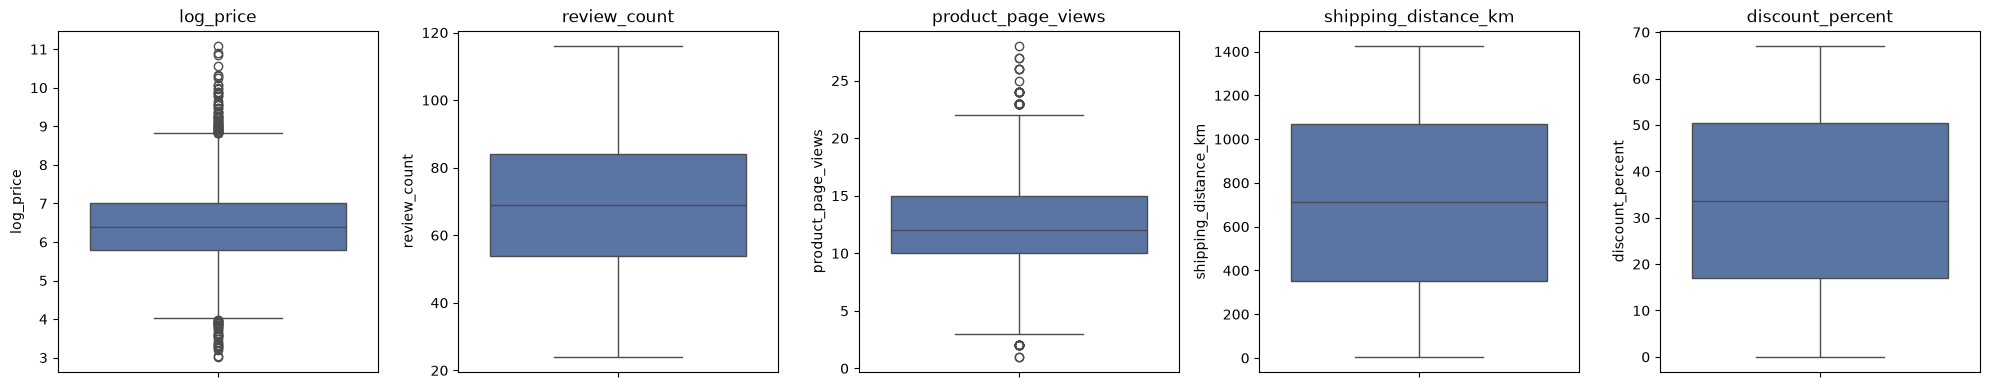

In [51]:
box_cols = ["log_price", "review_count", "product_page_views", "shipping_distance_km", "discount_percent"]
fig, axes = plt.subplots(1, len(box_cols), figsize = (20, 4))
for ax, c in zip(axes, box_cols):
    sns.boxplot(y = X_train[c], ax = ax, color = "#4c72b0")
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [52]:
outliers_cols = ["log_price"]
mask = pd.Series(True, index = X_train.index)
for c in outliers_cols:
    q1, q3 = X_train[c].quantile(0.25), X_train[c].quantile(0.75)
    upper = q3 + 3 * (q3 - q1)
    mask &= X_train[c] <= upper
removed = (~mask).sum()
X_train, Y_train = X_train[mask], Y_train[mask]
print(f"Removed {removed} extreme - outlier rows from training set. New Train shape {X_train.shape}")

Removed 3 extreme - outlier rows from training set. New Train shape (9597, 23)


In [53]:
X_train.head()

,product_category,sub_category,brand,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,...,seller_return_rate,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,total_support_contacts,log_price
6601,Fashion,Accessories,Brand_23,28.0,4.2,53.0,0,1,0.224,0.155,...,0.180,Marketplace Fulfilled,Wallet,5,910.0,0,1,13,0,5.726978
9297,Fashion,Accessories,Brand_18,13.7,2.9,34.0,0,0,0.071,0.089,...,0.001,Marketplace Fulfilled,Wallet,3,469.4,0,0,14,0,6.013960
6057,Fashion,Accessories,Brand_22,16.3,4.2,47.0,0,1,0.001,0.120,...,0.163,Marketplace Fulfilled,UPI,1,120.1,0,1,14,0,6.504243
8370,Home,Kitchen,Brand_6,31.3,4.1,59.0,1,1,0.077,0.081,...,0.183,Seller Fulfilled,COD,2,483.3,1,0,19,0,6.583063
6173,Fashion,Men,Brand_14,19.6,3.9,105.0,1,0,0.147,0.104,...,0.150,Seller Fulfilled,COD,3,879.8,0,1,9,1,6.185220


In [54]:
binary_flags = ["fragile_item", "warranty_available", "delayed_delivery", "wishlist_before_purchase"]
categorical_features = ["product_category", "sub_category", "brand", "fulfillment_type", "payment_method"]
numerical_features = [c for c in X_train.columns if c not in binary_flags + categorical_features]
all_features = numerical_features + binary_flags
X_train.isna().sum()

product_category              0
sub_category                  0
brand                         0
discount_percent              0
product_rating              199
review_count                 97
fragile_item                  0
warranty_available            0
product_return_rate           0
category_return_rate          0
brand_return_rate             0
defect_rate                   0
seller_rating               150
seller_return_rate            0
fulfillment_type              0
payment_method                0
quantity                      0
shipping_distance_km         90
delayed_delivery              0
wishlist_before_purchase      0
product_page_views            0
total_support_contacts        0
log_price                     0
dtype: int64

### SUBSTITUTING NA VALUES WITH MEDIAN

In [55]:
train_median = X_train[all_features].median().to_dict()
train_median

{'discount_percent': 33.5,
 'product_rating': 3.9,
 'review_count': 69.0,
 'product_return_rate': 0.134,
 'category_return_rate': 0.12,
 'brand_return_rate': 0.136,
 'defect_rate': 0.051,
 'seller_rating': 4.1,
 'seller_return_rate': 0.121,
 'quantity': 3.0,
 'shipping_distance_km': 714.1,
 'product_page_views': 12.0,
 'total_support_contacts': 1.0,
 'log_price': 6.389636457722005,
 'fragile_item': 0.0,
 'warranty_available': 0.0,
 'delayed_delivery': 0.0,
 'wishlist_before_purchase': 0.0}

In [56]:
X_train[all_features] = X_train[all_features].fillna(train_median)
X_test[all_features] = X_test[all_features].fillna(train_median)
X_train.isna().sum()

product_category            0
sub_category                0
brand                       0
discount_percent            0
product_rating              0
review_count                0
fragile_item                0
warranty_available          0
product_return_rate         0
category_return_rate        0
brand_return_rate           0
defect_rate                 0
seller_rating               0
seller_return_rate          0
fulfillment_type            0
payment_method              0
quantity                    0
shipping_distance_km        0
delayed_delivery            0
wishlist_before_purchase    0
product_page_views          0
total_support_contacts      0
log_price                   0
dtype: int64

In [63]:
print(X_train.columns.tolist())
print(categorical_features)
print(X_train.shape)
print(X_test.shape)
print(X_train.columns.equals(X_test.columns))
print(X_train.columns.intersection(categorical_features))

['discount_percent', 'product_rating', 'review_count', 'fragile_item', 'warranty_available', 'product_return_rate', 'category_return_rate', 'brand_return_rate', 'defect_rate', 'seller_rating', 'seller_return_rate', 'quantity', 'shipping_distance_km', 'delayed_delivery', 'wishlist_before_purchase', 'product_page_views', 'total_support_contacts', 'log_price', 'product_category_Beauty', 'product_category_Books', 'product_category_Electronics', 'product_category_Fashion', 'product_category_Home', 'product_category_Sports', 'product_category_Toys', 'sub_category_Academic', 'sub_category_Accessories', 'sub_category_Action Figures', 'sub_category_Audio', 'sub_category_Decor', 'sub_category_Educational', 'sub_category_Fiction', 'sub_category_Fitness', 'sub_category_Footwear', 'sub_category_Furniture', 'sub_category_Haircare', 'sub_category_Kids', 'sub_category_Kitchen', 'sub_category_Laptops', 'sub_category_Makeup', 'sub_category_Men', 'sub_category_Mobiles', 'sub_category_Non-Fiction', 'sub_c

In [66]:
scaler = StandardScaler()
X_train[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test[numerical_features] = scaler.transform(X_test[numerical_features])
print(X_train.columns.intersection(categorical_features))

Index([], dtype='str')


SCALING USING STANDARD SCALER

In [73]:
scaler = StandardScaler()
X_train[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test[numerical_features] = scaler.transform(X_test[numerical_features])
X_train = pd.get_dummies(X_train, columns = categorical_features, dtype = int)
X_test =  pd.get_dummies(X_test, columns = categorical_features, dtype = int)
X_test = X_test.reindex(columns = X_train.columns, fill_value = 0)
X_train.head(3)


,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,...,brand_Brand_7,brand_Brand_8,brand_Brand_9,fulfillment_type_Marketplace Fulfilled,fulfillment_type_Seller Fulfilled,payment_method_COD,payment_method_Credit Card,payment_method_Debit Card,payment_method_UPI,payment_method_Wallet
6601,-0.289835,0.499665,-0.882595,0,1,1.304095,0.700734,1.472360,-0.002869,0.014436,...,0,0,0,1,0,0,0,0,0,1
9297,-1.028678,-1.542934,-1.911385,0,0,-0.886022,-0.635926,-0.339150,-1.040254,-2.341345,...,0,0,0,1,0,0,0,0,0,1
6057,-0.894343,0.499665,-1.207476,0,1,-1.888036,-0.008101,-1.446183,-0.898792,0.871084,...,0,0,0,1,0,0,0,0,1,0


### TRAINING MULTIPLE MODELS TO SEE WHICH PERFORMS WELL

In [38]:
spw = (Y_train == 0).sum() / (Y_train == 1).sum()
models = {
    "Logistic Regression" : LogisticRegression(max_iter = 1000, class_weight = "balanced", random_state = RANDOM_STATE),
    "Decision Tree" : DecisionTreeClassifier(class_weight = "balanced", random_state = RANDOM_STATE),
    "Random Forest" : RandomForestClassifier(class_weight = "balanced", n_estimators = 300, n_jobs = -1, random_state = RANDOM_STATE),
    "XGBoostClassifier" : XGBClassifier(n_estimators = 300, learning_rate = 0.05, max_depth = 5, subsample = 0.9, colsample_bytree = 0.9, scale_pos_weight = spw, eval_metric = "logloss", random_state = RANDOM_STATE, n_jobs = -1)
}
fitted = {}
for name, est in models.items():
    est.fit(X_train, Y_train)
    fitted[name] = est
    print("Trained:", name)

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: XGBoostClassifier


### MODEL EVALUATION

In [39]:
def evaluate(model, X_test, Y_test):
    Y_pred_test = model.predict(X_test)
    return{
        "accuracy" : accuracy_score(Y_test, Y_pred_test),
        "precision" : precision_score(Y_test, Y_pred_test, zero_division = 0),
        "Recall" : recall_score(Y_test, Y_pred_test, zero_division = 0),
        "F1 score" : f1_score(Y_test, Y_pred_test, zero_division = 0)
    }
comparison = pd.DataFrame({name : evaluate(model, X_test, Y_test) for name, model in fitted.items()}).T
comparison = comparison.sort_values("F1 score", ascending = False)
comparison.round(4)

,accuracy,precision,Recall,F1 score
Logistic Regression,0.8558,0.7194,0.8615,0.7840
XGBoostClassifier,0.8471,0.7150,0.8258,0.7664
Random Forest,0.8488,0.7500,0.7531,0.7515
Decision Tree,0.7800,0.6345,0.6502,0.6423


### DATA VISUALIZATION

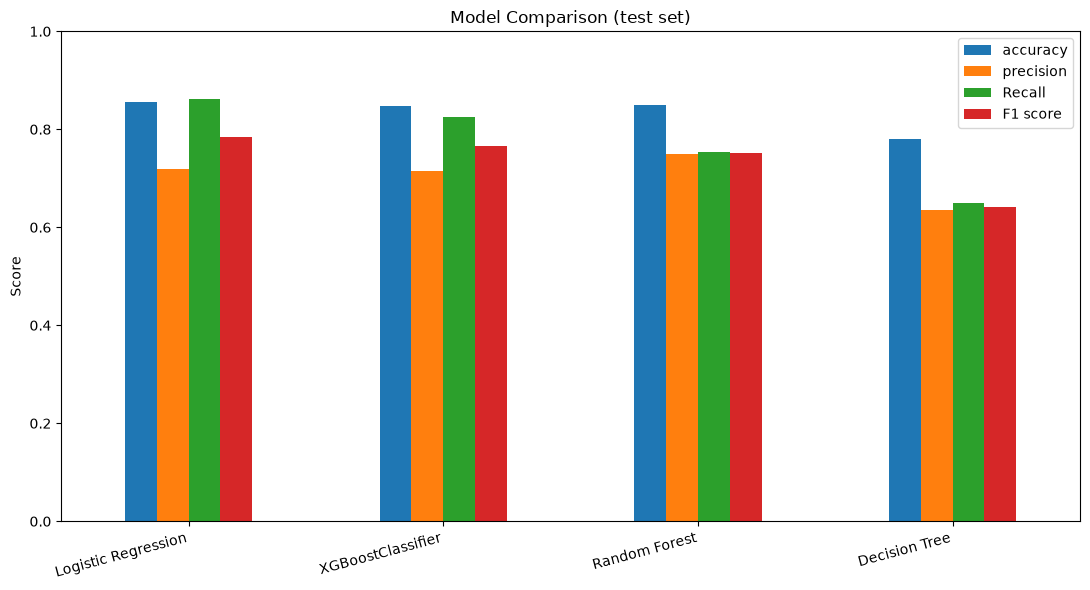

In [40]:
comparison.plot(kind = "bar", figsize = (11, 6))
plt.title("Model Comparison (test set)")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation = 15, ha = "right")
plt.tight_layout()
plt.show()

### BEST MODEL FINDING

In [41]:
best_name = comparison.index[0]
print(best_name)
fine_tune = fitted[best_name] 
tuned_metrics = evaluate(fine_tune, X_test, Y_test)
for k, v in tuned_metrics.items():
    print(f"{k:10s} : {v:.4f}")

Logistic Regression
accuracy   : 0.8558
precision  : 0.7194
Recall     : 0.8615
F1 score   : 0.7840


### CONFUSION MATRIX

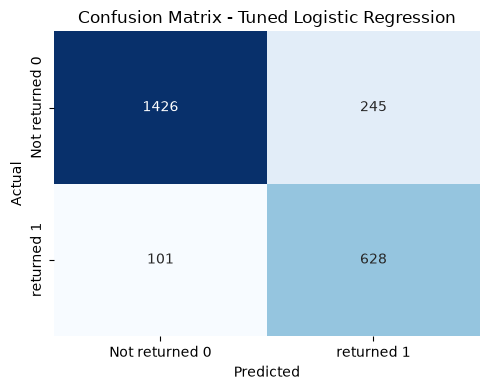

In [42]:
cm = confusion_matrix(Y_test, fine_tune.predict(X_test))
plt.figure(figsize = (5,4))
sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues", cbar = False, xticklabels = ["Not returned 0", "returned 1"], yticklabels = ["Not returned 0", "returned 1"])
plt.title(f"Confusion Matrix - Tuned {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [43]:
print(classification_report(Y_test, fine_tune.predict(X_test), target_names = ["Not returned", "Returned"], digits = 4))
fine_tune.coef_
fine_tune.intercept_

              precision    recall  f1-score   support

Not returned     0.9339    0.8534    0.8918      1671
    Returned     0.7194    0.8615    0.7840       729

    accuracy                         0.8558      2400
   macro avg     0.8266    0.8574    0.8379      2400
weighted avg     0.8687    0.8558    0.8591      2400



array([-0.85523428])

### PLOTTING ON A CHART

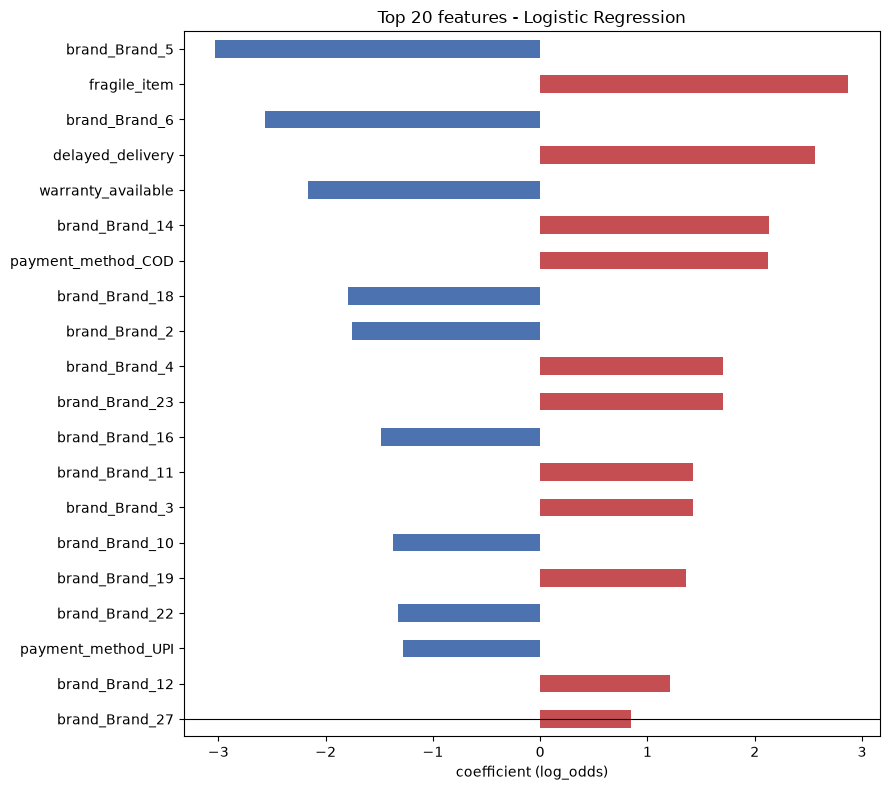

brand_Brand_5        -3.0272
fragile_item          2.8725
brand_Brand_6        -2.5675
delayed_delivery      2.5643
warranty_available   -2.1616
brand_Brand_14        2.1296
payment_method_COD    2.1233
brand_Brand_18       -1.7904
brand_Brand_2        -1.7540
brand_Brand_4         1.7075
brand_Brand_23        1.7068
brand_Brand_16       -1.4866
brand_Brand_11        1.4288
brand_Brand_3         1.4218
brand_Brand_10       -1.3705
brand_Brand_19        1.3553
brand_Brand_22       -1.3290
payment_method_UPI   -1.2751
brand_Brand_12        1.2058
brand_Brand_27        0.8482
dtype: float64

In [44]:
chart = pd.Series(fine_tune.coef_[0], index = X_train.columns)
top = chart.reindex(chart.abs().sort_values(ascending = False).index).head(20)
colors = ["#c44e52" if v>0 else "#4c72b0" for v in top]
plt.figure(figsize = (9, 8))
top[::-1].plot(kind = "barh", color = colors[::-1])
plt.axhline(0, color = "black", lw = 0.8)
plt.title(f"Top 20 features - {best_name}")
plt.xlabel("coefficient (log_odds)")
plt.tight_layout()
plt.show()
top.round(4)

### SAVING THE MODEL TO TEST

In [45]:
fi_values = np.abs(fine_tune.coef_[0])
fi_series = pd.Series(fi_values, index = X_train.columns).sort_values(ascending = False)
feature_importance = [{"feature" : k, "importance" : round(float(v), 6)} for k, v in fi_series.head(20).items()]
model_data = {
    "model" : fine_tune,
    "model_name" : best_name,
    "scalar" : scaler,
    "model_columns" : X_train.columns,
    "numeric_features" : numerical_features,
    "binary_features" : binary_flags,
    "categorical_features" : categorical_features,
    "train_medians" : train_median,
    "metrics" : tuned_metrics,
    "feature_importance" : feature_importance,
    "threshold" : 0.5
}

### USING JOBLIB TO DUMP AND LOAD THE DATA

In [46]:
joblib.dump(model_data, "artifacts/capstone.joblib")

['artifacts/capstone.joblib']

In [47]:
return_predict_


NameError: name 'return_predict_' is not defined